<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2024%3A%20Graphical%20Model%20Sampling%20and%20Probabilistic%20Inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

              Query  Exact  Forward Rejection
XRay=Pos, Cough=Yes 0.7934   0.7640     0.788
      + Smoking=Yes 0.9160   0.8772         -


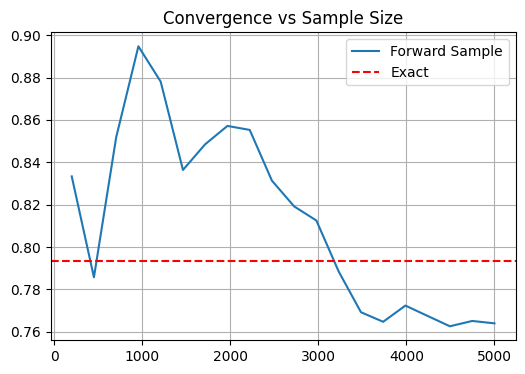

In [2]:
import subprocess, sys
try:
    import pgmpy
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pgmpy"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

bn = DiscreteBayesianNetwork([('Pollution', 'LungDisease'), ('Smoking', 'LungDisease'),
                              ('LungDisease', 'XRay'), ('LungDisease', 'Cough'), ('LungDisease', 'Fatigue')])
bn.add_cpds(
    TabularCPD('Pollution', 2, [[0.9], [0.1]], state_names={'Pollution': ['Low', 'High']}),
    TabularCPD('Smoking', 2, [[0.7], [0.3]], state_names={'Smoking': ['No', 'Yes']}),
    TabularCPD('LungDisease', 2, [[0.99, 0.90, 0.95, 0.70], [0.01, 0.10, 0.05, 0.30]],
               evidence=['Pollution', 'Smoking'], evidence_card=[2, 2],
               state_names={'LungDisease': ['No', 'Yes'], 'Pollution': ['Low', 'High'], 'Smoking': ['No', 'Yes']}),
    TabularCPD('XRay', 2, [[0.95, 0.20], [0.05, 0.80]], evidence=['LungDisease'], evidence_card=[2],
               state_names={'XRay': ['Neg', 'Pos'], 'LungDisease': ['No', 'Yes']}),
    TabularCPD('Cough', 2, [[0.85, 0.25], [0.15, 0.75]], evidence=['LungDisease'], evidence_card=[2],
               state_names={'Cough': ['No', 'Yes'], 'LungDisease': ['No', 'Yes']}),
    TabularCPD('Fatigue', 2, [[0.80, 0.30], [0.20, 0.70]], evidence=['LungDisease'], evidence_card=[2],
               state_names={'Fatigue': ['No', 'Yes'], 'LungDisease': ['No', 'Yes']})
)

inf = VariableElimination(bn)
q1 = inf.query(['LungDisease'], evidence={'XRay': 'Pos', 'Cough': 'Yes'}).values[1]
q2 = inf.query(['LungDisease'], evidence={'XRay': 'Pos', 'Cough': 'Yes', 'Smoking': 'Yes'}).values[1]

smp = BayesianModelSampling(bn)
fwd = smp.forward_sample(size=5000, show_progress=False)
rej = smp.rejection_sample(evidence=[('XRay', 'Pos'), ('Cough', 'Yes')], size=500, show_progress=False)

f_q1 = (fwd[(fwd['XRay']=='Pos') & (fwd['Cough']=='Yes')]['LungDisease'] == 'Yes').mean()
f_q2 = (fwd[(fwd['XRay']=='Pos') & (fwd['Cough']=='Yes') & (fwd['Smoking']=='Yes')]['LungDisease'] == 'Yes').mean()
r_q1 = (rej['LungDisease'] == 'Yes').mean()

print(pd.DataFrame([
    {'Query': 'XRay=Pos, Cough=Yes', 'Exact': round(q1, 4), 'Forward': round(f_q1, 4), 'Rejection': round(r_q1, 4)},
    {'Query': '+ Smoking=Yes', 'Exact': round(q2, 4), 'Forward': round(f_q2, 4), 'Rejection': '-'}
]).to_string(index=False))

sizes = np.linspace(200, 5000, 20, dtype=int)
ests = [(fwd.iloc[:s][(fwd.iloc[:s]['XRay']=='Pos') & (fwd.iloc[:s]['Cough']=='Yes')]['LungDisease'] == 'Yes').mean() for s in sizes]
plt.figure(figsize=(6, 4))
plt.plot(sizes, ests, label='Forward Sample')
plt.axhline(q1, color='r', linestyle='--', label='Exact')
plt.title("Convergence vs Sample Size")
plt.legend()
plt.grid(True)
plt.show()